# Q1x — Joint anchor structure: velocity x merchant_risk

The adjacent idea (2026-11-22): analyze the anchors of the two score
columns *jointly*. The unit is the 2-D cell (velocity anchor, risk
anchor). Question: does the joint cell explain fraud better than each
column's anchor alone — in particular, does the partner column's anchor
explain the rate variance that the 1-D analysis leaves inside a single
column's anchors?

Two sub-questions, kept separate on purpose:

- **Partner explains variance** (no new mechanism): inside a velocity
  anchor, fraud rate varies with the risk anchor simply because risk
  carries its own rate structure. Checked visually: rate vs partner
  anchor within the biggest anchors, against the anchor's own overall
  rate.
- **Beyond-marginal interaction** (new mechanism): cells whose rate
  deviates from what the two marginal anchor rates already predict.
  Checked with a lift map (cell rate / independence-expected rate,
  log-odds combination of the two marginal shrunk anchor rates) and a
  simulation test: redraw labels from the independence-expected rates
  and see whether the real cell field deviates more.

Machinery identical to Q1: frozen unified alarm-profile folds; per-cell
rates are the mean of the per-fold ratios; bootstrap CIs resample fraud
counts as Binomial(n_cell, cell rate), B = 200; cells with < 50 rows are
masked from rate displays. Marginal anchor rates for the expected-rate
map use the full train with k = 20 shrinkage (pooled; the simulation is
the honest reference).

Interpretation deliberately deferred.

In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ccf_ml.cross_validation.constants import ID_COLUMN, TARGET_COLUMN
from ccf_ml.file_utils import get_script_plot_dir, get_train_csv_path
from ccf_ml.region_modeling import load_alarm_profile_stratified_cv

MIN_CELL_ROWS = 50
TOP_ANCHORS = 6
B = 200
SHRINK = 20
rng = np.random.default_rng(42)

train = pd.read_csv(get_train_csv_path())
y = train[TARGET_COLUMN].to_numpy(dtype=bool)

cv = load_alarm_profile_stratified_cv()
ids = train[ID_COLUMN].to_numpy(dtype=np.int64)
fold_of = np.full(len(train), -1, dtype=np.int64)
pos_by_id = np.full(int(ids.max()) + 1, -1, dtype=np.int64)
pos_by_id[ids] = np.arange(len(ids))
for fold in cv.folds:
    for record_id in fold.val_ids:
        fold_of[pos_by_id[int(record_id)]] = fold.fold_id
assert (fold_of >= 0).all()

va = np.floor(train["velocity_score"].to_numpy(dtype=np.float64)).astype(np.int64)
ra = np.floor(train["merchant_risk_score"].to_numpy(dtype=np.float64)).astype(np.int64)

plot_dir = get_script_plot_dir(
    "q1_joint_anchor_structure", section="joint", group="numerical_grid_structure"
)
global_rate = float(y.mean())
print("rows:", len(train), "| global rate:", round(global_rate, 4), "| plots ->", plot_dir)

Creating missing directory: C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\numerical_grid_structure\q1_joint_anchor_structure\plots\joint


rows: 699960 | global rate: 0.0167 | plots -> C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\numerical_grid_structure\q1_joint_anchor_structure\plots\joint


In [2]:
# per-cell table: (velocity anchor, risk anchor) -> rows, frauds, CV-mean rate
cell_frame = pd.DataFrame({"va": va, "ra": ra, "y": y, "fold": fold_of})
cells = cell_frame.groupby(["va", "ra"])["y"].agg(fraud_total="sum", rows_total="size")
fold_rates = []
for fold_id in range(cv.n_splits):
    sub = cell_frame[cell_frame["fold"] == fold_id]
    fold_rates.append(sub.groupby(["va", "ra"])["y"].mean().rename(fold_id))
per_fold = pd.concat(fold_rates, axis=1)
cells = cells.join(per_fold)
cells["cv_mean_rate"] = per_fold.mean(axis=1)
cells["pooled_rate"] = cells["fraud_total"] / cells["rows_total"]

shown = cells[cells["rows_total"] >= MIN_CELL_ROWS]
print(f"cells total: {len(cells)} | cells >= {MIN_CELL_ROWS} rows: {len(shown)}")
print(
    f"rows in shown cells: {int(shown['rows_total'].sum())} "
    f"({shown['rows_total'].sum() / len(train):.1%}) | "
    f"frauds in shown cells: {int(shown['fraud_total'].sum())} "
    f"({shown['fraud_total'].sum() / y.sum():.1%})"
)
print(
    "shown-cell rate range:",
    round(float(shown["cv_mean_rate"].min()), 4),
    "to",
    round(float(shown["cv_mean_rate"].max()), 4),
    f"({float(shown['cv_mean_rate'].max() - shown['cv_mean_rate'].min()) / global_rate:.1f}x global)",
)

# marginal anchor rates (full train, shrunk k=20) for the expected-rate map
va_stats = cell_frame.groupby("va")["y"].agg(["sum", "size"])
va_rate = (va_stats["sum"] + SHRINK * global_rate) / (va_stats["size"] + SHRINK)
ra_stats = cell_frame.groupby("ra")["y"].agg(["sum", "size"])
ra_rate = (ra_stats["sum"] + SHRINK * global_rate) / (ra_stats["size"] + SHRINK)

def logit(p):
    return np.log(p / (1.0 - p))

logit_global = logit(global_rate)
exp_rate = {}
for (v, r), row in cells.iterrows():
    lv = logit(float(va_rate.loc[v])) + logit(float(ra_rate.loc[r])) - logit_global
    exp_rate[(v, r)] = 1.0 / (1.0 + np.exp(-lv))
cells["expected_rate"] = pd.Series(exp_rate)
cells["lift"] = cells["cv_mean_rate"] / cells["expected_rate"]
print("expected-rate table built (marginals, k=20 shrinkage)")

cells total: 5129 | cells >= 50 rows: 2121
rows in shown cells: 664781 (95.0%) | frauds in shown cells: 8874 (75.9%)
shown-cell rate range: 0.0 to 0.2465 (14.8x global)


expected-rate table built (marginals, k=20 shrinkage)


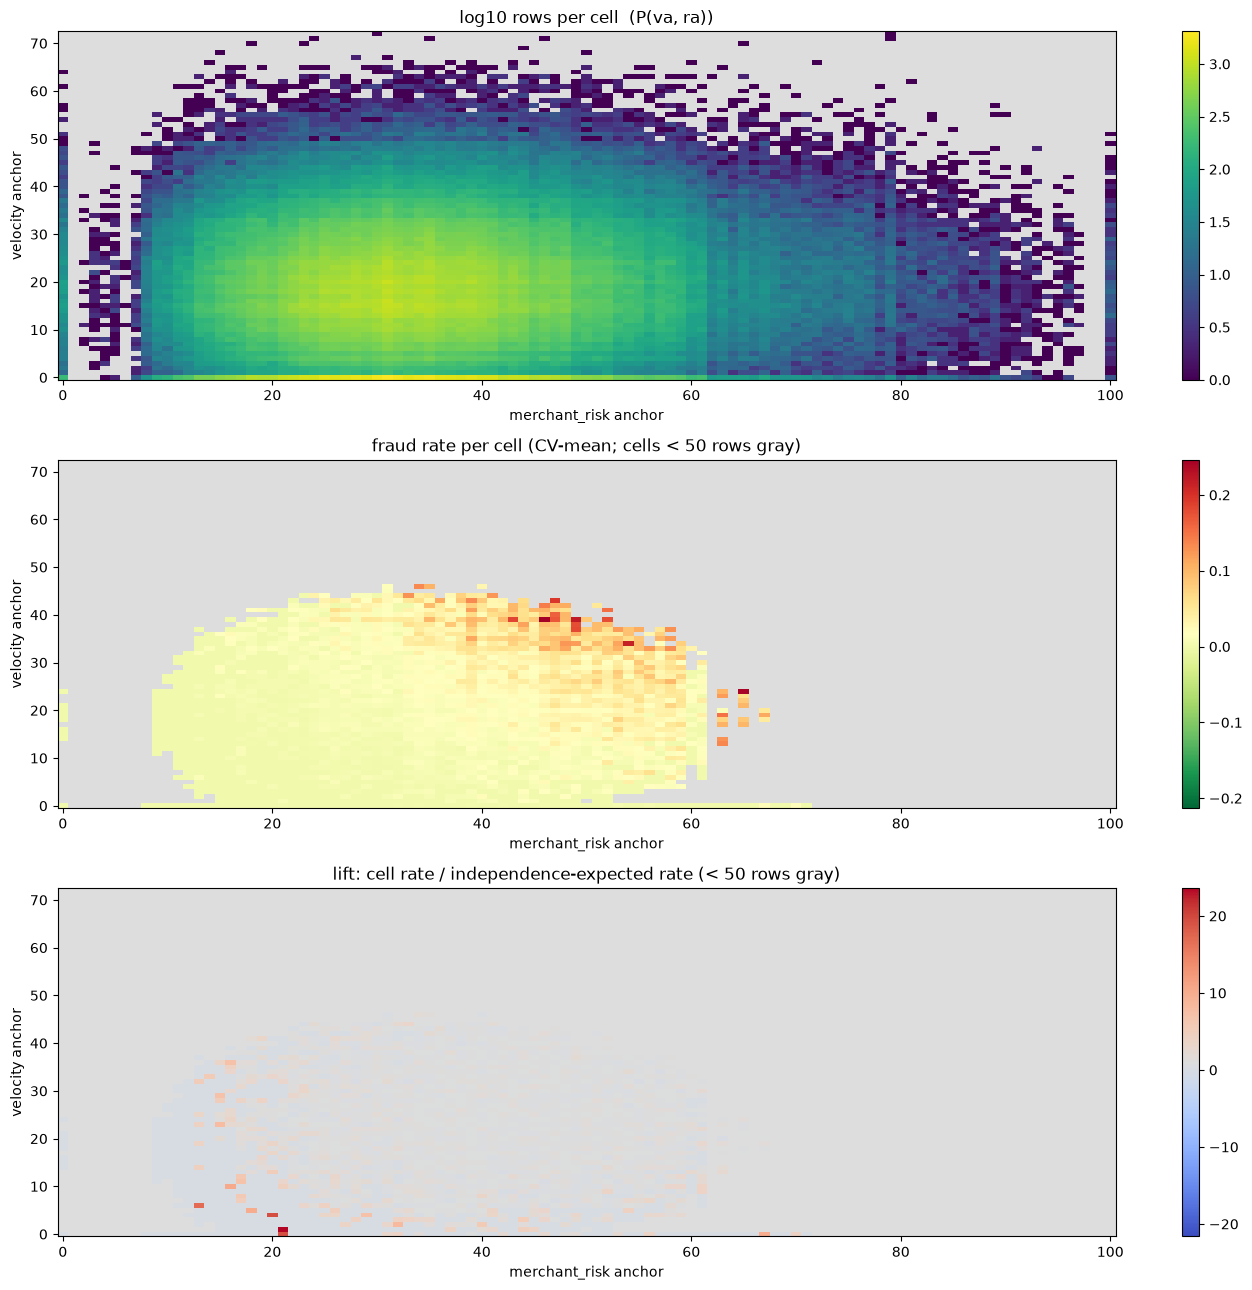

In [3]:
# heat maps: counts, observed CV-mean rate, lift vs independence
va_axis = np.arange(va.min(), va.max() + 1)
ra_axis = np.arange(ra.min(), ra.max() + 1)

def to_matrix(values, mask_min_rows):
    grid = np.full((len(va_axis), len(ra_axis)), np.nan)
    v_pos = {v: i for i, v in enumerate(va_axis)}
    r_pos = {r: i for i, r in enumerate(ra_axis)}
    for (v, r), row in cells.iterrows():
        if mask_min_rows and row["rows_total"] < MIN_CELL_ROWS:
            continue
        grid[v_pos[v], r_pos[r]] = values.loc[(v, r)]
    return grid

counts = to_matrix(cells["rows_total"], mask_min_rows=False)
rate = to_matrix(cells["cv_mean_rate"], mask_min_rows=True)
lift = to_matrix(cells["lift"], mask_min_rows=True)

fig, axes = plt.subplots(3, 1, figsize=(14, 13))
for ax, grid, title, cmap, vmid in [
    (axes[0], np.log10(counts), "log10 rows per cell  (P(va, ra))", "viridis", None),
    (axes[1], rate, "fraud rate per cell (CV-mean; cells < 50 rows gray)", "RdYlGn_r", global_rate),
    (axes[2], lift, "lift: cell rate / independence-expected rate (< 50 rows gray)", "coolwarm", 1.0),
]:
    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad(color="#dddddd")
    im = ax.pcolormesh(ra_axis, va_axis, grid, cmap=cmap_obj, shading="nearest")
    if vmid is not None:
        absmax = np.nanmax(np.abs(grid - vmid))
        im.set_clim(vmid - absmax, vmid + absmax)
    ax.set_xlabel("merchant_risk anchor")
    ax.set_ylabel("velocity anchor")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(plot_dir / "joint_anchor_heatmaps.png", dpi=110)
plt.show()

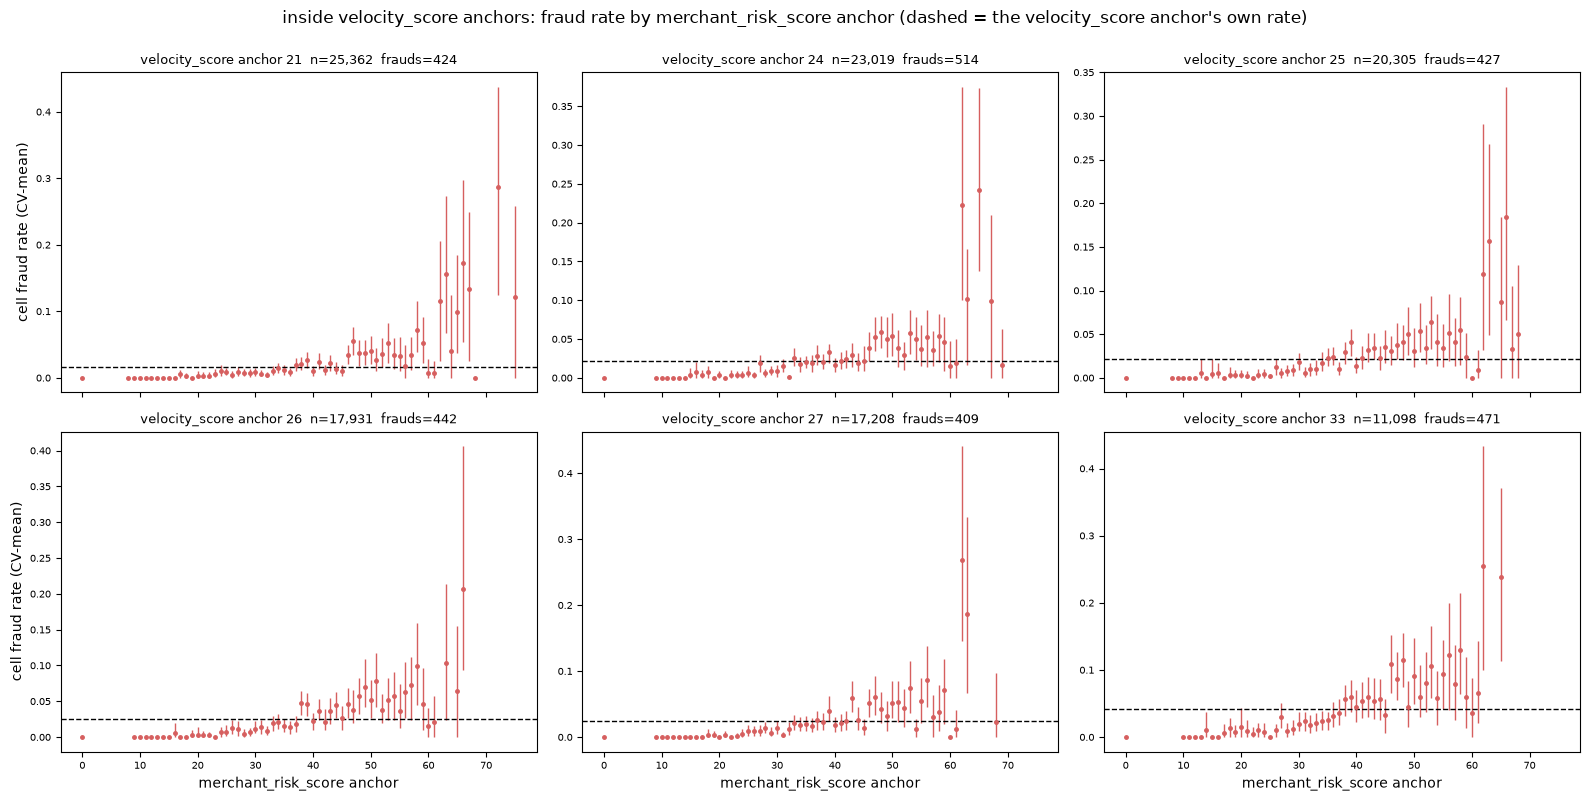

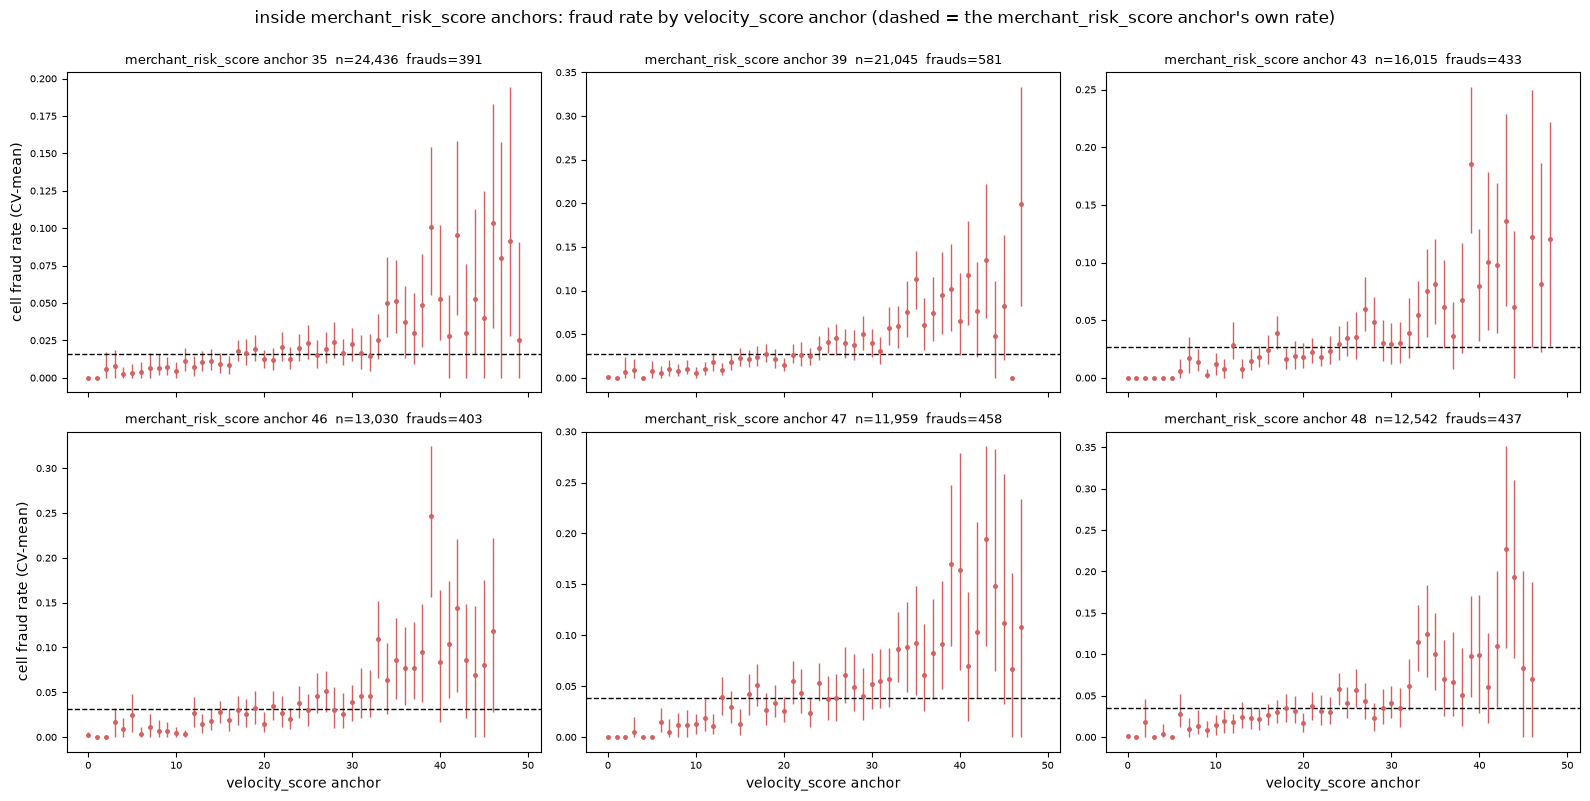

In [4]:
# within one column's anchors: does the partner column explain the variance?
for primary, partner, primary_name, partner_name in [
    (va, ra, "velocity_score", "merchant_risk_score"),
    (ra, va, "merchant_risk_score", "velocity_score"),
]:
    frame = pd.DataFrame({"a": primary, "b": partner, "y": y})
    anchor_tot = frame.groupby("a")["y"].agg(fraud_total="sum", rows_total="size")
    top = anchor_tot.sort_values("fraud_total", ascending=False).head(TOP_ANCHORS).sort_index()
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
    for ax, (a_val, a_row) in zip(axes.ravel(), top.iterrows()):
        sub = cells.xs(a_val, level=("va" if primary is va else "ra"))
        sub = sub[sub["rows_total"] >= 30]
        n = sub["rows_total"].to_numpy(dtype=np.int64)
        p = sub["cv_mean_rate"].to_numpy()
        draws = rng.binomial(n[:, None], p[:, None], size=(len(sub), B)) / n[:, None]
        lo, hi = np.percentile(draws, [2.5, 97.5], axis=1)
        rate_line = float(a_row["fraud_total"] / a_row["rows_total"])
        ax.errorbar(
            sub.index, p,
            yerr=np.vstack([np.clip(p - lo, 0, None), np.clip(hi - p, 0, None)]),
            fmt=".", ms=5, lw=1, color="#d65f5f", ecolor="#d65f5f",
        )
        ax.axhline(rate_line, color="black", lw=1, ls="--")
        ax.set_title(
            f"{primary_name} anchor {a_val}  n={int(a_row['rows_total']):,}  "
            f"frauds={int(a_row['fraud_total'])}", fontsize=9,
        )
        ax.tick_params(labelsize=7)
    for ax in axes[-1]:
        ax.set_xlabel(f"{partner_name} anchor")
    axes[0, 0].set_ylabel("cell fraud rate (CV-mean)")
    axes[1, 0].set_ylabel("cell fraud rate (CV-mean)")
    fig.suptitle(
        f"inside {primary_name} anchors: fraud rate by {partner_name} anchor "
        f"(dashed = the {primary_name} anchor's own rate)", y=0.995
    )
    fig.tight_layout()
    fig.savefig(plot_dir / f"within_{primary_name}_by_partner.png", dpi=110)
    plt.show()

In [5]:
# beyond-marginal interaction: simulation from the independence-expected rates
# statistic: Pearson-style divergence of observed cell frauds from expected,
# over cells with >= 100 rows. Null: frauds drawn per row from the
# independence-expected rate (marginals fitted on the same train, so the
# null is conservative: any signal the fit absorbed is removed from both).
big = cells[cells["rows_total"] >= 100].copy()
obs_fraud = big["fraud_total"].to_numpy(dtype=np.int64)
exp_fraud = (big["rows_total"] * big["expected_rate"]).to_numpy(dtype=np.float64)
t_obs = float(((obs_fraud - exp_fraud) ** 2 / exp_fraud).sum())

row_exp = pd.Series(list(zip(va, ra))).map(exp_rate).to_numpy(dtype=np.float64)
n_sim = 200
null = np.empty(n_sim)
for b in range(n_sim):
    sim_y = rng.binomial(1, row_exp).astype(bool)
    sim_frame = pd.DataFrame({"va": va, "ra": ra, "y": sim_y})
    agg = sim_frame.groupby(["va", "ra"])["y"].agg(fraud="sum", rows="size")
    sim_fraud = agg.reindex(big.index)["fraud"].to_numpy(dtype=np.int64)
    null[b] = (((sim_fraud - exp_fraud) ** 2) / exp_fraud).sum()
p_value = (1 + int((null >= t_obs).sum())) / (n_sim + 1)
print(f"cells >= 100 rows: {len(big)} | T_obs = {t_obs:.1f} | "
      f"null median = {np.median(null):.1f} | null 95th = {np.percentile(null, 95):.1f} | "
      f"simulated p = {p_value:.4f}")

# within-anchor spread: observed vs binomial-only expectation
rows = []
for primary, primary_name in [(va, "velocity_score"), (ra, "merchant_risk_score")]:
    frame = pd.DataFrame({"a": primary, "y": y})
    anchor_tot = frame.groupby("a")["y"].agg(fraud_total="sum", rows_total="size")
    big_anchors = anchor_tot[anchor_tot["fraud_total"] >= 100]
    spreads_obs, spreads_exp = [], []
    for a_val, a_row in big_anchors.iterrows():
        rate_a = float(a_row["fraud_total"] / a_row["rows_total"])
        sub = cells.xs(a_val, level=("va" if primary is va else "ra"))
        sub = sub[sub["rows_total"] >= 50]
        if len(sub) < 5:
            continue
        w = sub["rows_total"] / sub["rows_total"].sum()
        mean_rate = float((w * sub["cv_mean_rate"]).sum())
        spreads_obs.append(float((w * (sub["cv_mean_rate"] - mean_rate) ** 2).sum()))
        p = sub["cv_mean_rate"]
        spreads_exp.append(float((w * p * (1 - p) / sub["rows_total"]).sum()))
    rows.append({
        "column": primary_name,
        "anchors (>=100 frauds, >=5 big cells)": len(spreads_obs),
        "median observed within-anchor rate variance": round(float(np.median(spreads_obs)), 7),
        "median binomial-only variance": round(float(np.median(spreads_exp)), 7),
        "ratio": round(float(np.median(spreads_obs) / np.median(spreads_exp)), 2),
    })
pd.DataFrame(rows)

cells >= 100 rows: 1703 | T_obs = 1598.6 | null median = 1667.3 | null 95th = 1807.5 | simulated p = 0.7960


,column,"anchors (>=100 frauds, >=5 big cells)",median observed within-anchor rate variance,median binomial-only variance,ratio
0,velocity_score,36,0.000282,0.000066,4.25
1,merchant_risk_score,37,0.000357,0.000079,4.52


## Interpretation

Written 2026-11-22, after review.

- The partner anchor DOES explain within-anchor variance: median
  within-anchor rate variance is 4.25x (velocity) / 4.52x (risk) the
  binomial-only expectation, and the small multiples show consistent climbs
  along the partner anchor inside fixed anchors. Most of the variance the
  1-D analysis left inside anchors is the partner column's own ramp.
- But the joint field is essentially the PRODUCT of the two marginals: the
  lift map is flat wherever cells are dense, and the independence
  simulation gives p = 0.796 (observed divergence below the null - the same
  sub-binomial regularity seen elsewhere). The counts map shows the two
  anchors fill roughly independently (dense low-x-low blob, no ridge).
- Reading: a joint (velocity x risk) rate feature would restate what
  arate/arate10 already hand the trees - consistent with anchor_v3's flat
  result, now established at the data level. The untested branch of the
  intersection hypothesis is anchors x CATEGORICAL features (mixture scan),
  which this notebook does not cover.